# A real1888 film as an inverse matrix problem


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `historic_film_low_rank_separation` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：frames (1, 84, 240, 320) uint8：Digital grayscale intensity in ADU; axes batch,time,y,x.。恢复目标：完整movie的低秩L与稀疏S，有符号normalized ADU。

获取模型：数字视频D=L+S；持久结构低秩、时变分量稀疏是明确结构统计获取模型。实际恢复算法：solvers.decompose/reconstruct：核范数阈值与L1 soft-threshold ADMM。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:45是方法分解L/S，没有真实分量标签或物理背景真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：historic_film_low_rank_separation.ipynb单元4：5. Results；historic_film_low_rank_separation.ipynb单元7：Independent reference and executed comparisons；historic_film_low_rank_separation.ipynb单元10有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元10（从0计数）。代码单元4个，带execution_count的4个，保存PNG输出4幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：属于结构统计分解inverse，不是已校准物理radiance、真实静态背景或真实运动分割。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Separate persistent image structure and sparse temporal changes from a complete real historical film despite camera jitter, film texture and overlapping motion.

This notebook actively reconstructs the bound observations using only cleaned local modules. Historical paper reports, the separately captured original run and fresh measurements are not interchanged. The original run was1657 iterations; its default1000 budget was insufficient and was increased before extraction without relaxing the1e-7 relative additive tolerance.


## 2. Data

`data/raw_data.npz` contains the entire decoded grayscale movie. Conversion from the source's slightly tinted color encoding used the standard BT.601 digital grayscale convention; no crop, resize, added corruption or temporal averaging was applied.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| frames | (1, 84, 240, 320) | uint8 | Digital grayscale intensity in ADU; axes batch,time,y,x. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Historical scene | Traffic Crossing Leeds Bridge,1888 | identifier | Original film by Louis Le Prince. |
| Native digital frame count | 84 | frames | Every decoded frame is retained in order. |
| Native digital image dimensions | 240 by320 | pixels | Downward y and rightward x. |
| Grayscale convention | BT.601 digital luminance | ADU | Conversion from decoded color samples; intensity is not calibrated radiance. |
| Numeric intensity scale | D=frames/255 | normalized ADU | Exact normalization used by the observation model. |
| Pixel flattening | C-order (y,x), images as columns | convention | Pixel index y*320+x; matrix shape (76800,84). |
| Digital playback rate | 29.97002997002997 | frames/s | Container playback timing only; the1888 camera rate is unverified. |
| Physical pixel size, exposure and camera response | unavailable | uncalibrated | No physical spatial or radiometric scale is inferred. |
| Boundary treatment | no spatial or temporal extension | convention | The finite native image matrix is decomposed directly. |
| Noise model | uncalibrated recording/film/digitization variability | normalized ADU | No known Gaussian variance or photon count calibration is imposed. |

The original film is public domain; the source's rights statement identifies Public Domain Mark1.0 and applicable expired copyrights. Digital sampling does not create a calibrated physical acquisition clock.


All84 native frames of **Traffic Crossing Leeds Bridge** are observed digital intensity. The low-rank and signed sparse components are statistical estimands, **not true static scene or foreground labels**. The public-domain film has no component ground truth. We preserve camera jitter, borders, texture and every pixel.


## 3. Physics

Analyze all84 native digital frames of Traffic Crossing Leeds Bridge, recorded in1888 and preserved as a public-domain digital film. Let T=84, H=240, W=320. Flatten each image in row-major (y,x) order to form D in real pixels-by-time coordinates, with measured uint8 intensity divided by255. The additive observation model is


$$
D=L+S+E.
$$


Here D has HW rows and T columns, L is a low-rank image sequence, S is a signed sparse change sequence, and E is the residual in normalized digital intensity units. The components overlap in support and are not uniquely identifiable without structural assumptions. The complete native field includes film grain, borders, scene motion and camera jitter; no supplied mask isolates moving objects. No independent component truth or calibrated noise distribution is available.


## 4. Method

### Model, physical scale and algorithm

Define D[yW+x,t]=I[t,y,x]/255 for T=84,H=240,W=320. Thus D is a76800-by84 matrix in normalized digital intensity units. There is no resampling, centering or known physical radiance/pixel scale. The additive model is D=L+S+E, where L is low rank, S contains signed sparse changes and E is the residual.

Principal component pursuit minimizes ||L||_*+lambda||S||_1 subject to D=L+S. Here nuclear norm sums singular values and L1 norm sums entrywise absolute values. Starting S=Y=0, fixed mu=D.size/(4 sum(abs(D))) and lambda=1/sqrt(max(D.shape)), perform L=SVT(D-S+Y/mu,1/mu), S=soft(D-L+Y/mu,lambda/mu), Y=Y+mu(D-L-S). Soft thresholding removes magnitudes below its threshold; SVT applies it to singular values. The local small Gram eigenproblem evaluates this same proximal formula and was independently compared with the source SVD at all stages and full outputs. Stop at relative Frobenius residual1e-7 or3000 iterations. Every component remains signed and unclipped.

**Primary preprint printing discrepancy:** the archived v1 page29 prints signs/thresholds inconsistent with its own positive-dual augmented objective. Completing the square gives both positive Y/mu shifts and thresholds1/mu and lambda/mu. The selected original executable code already uses these consistent updates, which this notebook preserves and independently tests. Details and the rendered page are indexed in test/validation.md; no source-method change is hidden.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
from pathlib import Path
import os,sys,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib','inline')
ROOT=Path.cwd()
if not (ROOT/'src/main.py').exists(): ROOT=ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,as_matrix
from src.main import run
from src.visualization import summary,experiments,figures,export
frames=load_data()
print('Cleaned interpreter:',sys.executable,'full native movie:',frames.shape,frames.dtype)
print('CPU thread budget:',os.environ.get('OPENBLAS_NUM_THREADS','backend default'))


Cleaned interpreter: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe full native movie: (84, 240, 320) uint8
CPU thread budget: 1


In [2]:
start=time.perf_counter()
result,diag=run()
canonical_seconds=time.perf_counter()-start
diag['runtime_seconds']=canonical_seconds
fresh=summary(result,diag);fresh['seconds']=canonical_seconds
print('Fresh complete native reconstruction:',json.dumps(fresh,indent=2))
assert diag['converged'] and diag['relative_primal']<=1e-7
command=[sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json']
p=subprocess.run(command,capture_output=True,text=True)
assert p.returncode==0,p.stdout+p.stderr
report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
print('Independent Judge:',json.dumps(report,indent=2))
Path('notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps({'fresh':fresh,'judge':report},indent=2,allow_nan=False),encoding='utf8')


Fresh complete native reconstruction: {
  "iterations": 1657,
  "converged": true,
  "relative_primal": 9.999964969725234e-08,
  "lambda": 0.0036084391824351605,
  "rank_1e_6": 24,
  "sparse_fraction_1e_3": 0.3727411954365079,
  "low_energy": 799490.9311395669,
  "sparse_energy": 10000.705500756354,
  "seconds": 401.76239290018566
}


Independent Judge: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_relative_l2": 2.1566921112162632e-13,
    "sparse_component_relative_l2": 1.8938888051669213e-12,
    "additive_consistency_relative": 9.999964969725261e-08
  },
  "thresholds": {
    "reconstruction_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "sparse_component_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "additive_consistency_relative": {
      "comparison": "<=",
      "boundary": 1.1e-07
    }
  },
  "errors": []
}


951

### Independent reference and executed comparisons

The original source run below used these exact full observations, fixed parameters and original SVD proximal operation in a separately captured process before local extraction. It is a standard-method reconstruction, not truth. The source/local full arrays, first dual/proximal updates and full convergence trace are tested independently. We plot the original trace for comparison; **no archived reconstruction replaces a fresh result**.

Next we actually reconstruct full84-frame movies with lambda multiplied by0.75 and1.25. Temporal subsets retain every2nd/4th digital frame and are labeled sampling experiments, not changes in verified1888 exposure. Every variant reports actual stopping status. Rank1/3/5 PCA is freshly computed as an alternative decomposition. A descriptive sparse fraction uses |S|>1e-3; numerical rank uses singular values above1e-6 of their maximum. Neither statistic is accuracy against truth.


In [3]:
original=json.loads(Path('notebooks/reference_outputs/upstream_measurements.json').read_text(encoding='utf8'))
with np.load('notebooks/reference_outputs/upstream_trace.npz',allow_pickle=False) as z:
    print('Archived trace keys:',z.files)
    upstream=z[z.files[0]]
print('Independently reproduced original:',{k:original[k] for k in ['seconds','iterations','mu','lambda','final_relative_primal']})
start=time.perf_counter()
exp=experiments(frames,result,diag)
experiment_seconds=time.perf_counter()-start
print('Actual experiment seconds:',experiment_seconds)
for row in exp['records']:print(row)


Archived trace keys: ['history']
Independently reproduced original: {'seconds': 1052.4688039999455, 'iterations': 1657, 'mu': 0.9481384165894786, 'lambda': 0.0036084391824351605, 'final_relative_primal': 9.999964969747064e-08}


Actual experiment seconds: 1410.9757387000136
{'iterations': 1491, 'converged': True, 'relative_primal': 9.99827301133002e-08, 'lambda': 0.0027063293868263704, 'rank_1e_6': 21, 'sparse_fraction_1e_3': 0.5102013578869048, 'low_energy': 767693.2775682388, 'sparse_energy': 22179.743764785104, 'condition': 'lambda', 'factor': 0.75, 'seconds': 350.80192129989155}
{'iterations': 1657, 'converged': True, 'relative_primal': 9.999964969725234e-08, 'lambda': 0.0036084391824351605, 'rank_1e_6': 24, 'sparse_fraction_1e_3': 0.3727411954365079, 'low_energy': 799490.9311395669, 'sparse_energy': 10000.705500756354, 'condition': 'lambda', 'factor': 1.0, 'seconds': 401.76239290018566}
{'iterations': 2622, 'converged': True, 'relative_primal': 9.996274941497949e-08, 'lambda': 0.004510548978043951, 'rank_1e_6': 34, 'sparse_fraction_1e_3': 0.2990975322420635, 'low_energy': 814226.5751807244, 'sparse_energy': 5092.667350161013, 'condition': 'lambda', 'factor': 1.25, 'seconds': 644.6642123998608}
{'iteration

### Complete-data visual evidence

Selected frames display the complete native field. Raw values use0–255ADU, L uses a fixed0–1 display range, and S uses a common signed diverging scale per comparison. Signed components are never clipped in numerical results; display ranges are for viewing only. Every frame contributes to reconstruction, norms and energy curves. The convergence comparison, all-frame residuals and singular spectra are computed from fresh arrays. Sparse maps may include grain, illumination, jitter and persistent movement; no segmentation quality is inferred.


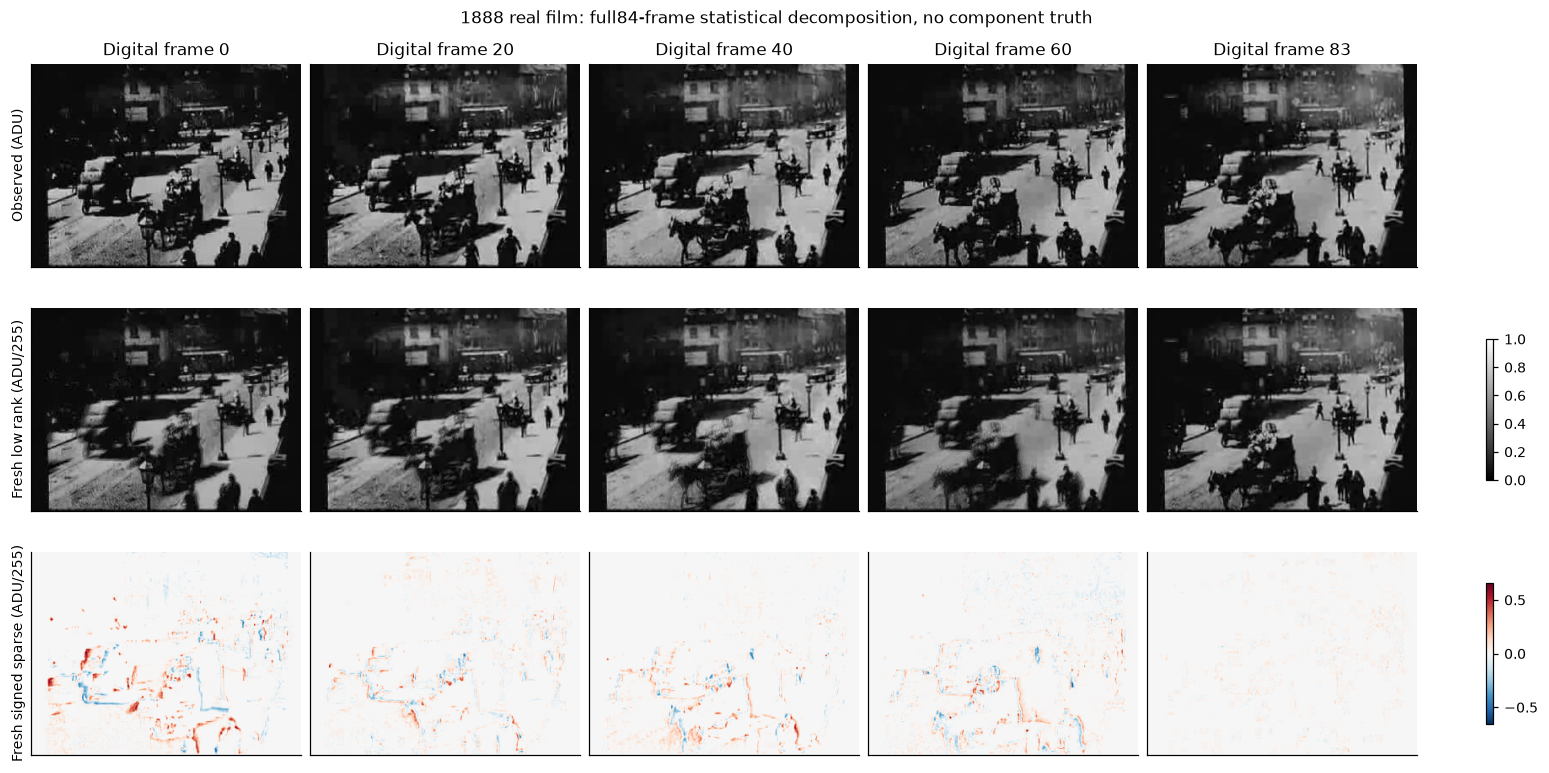

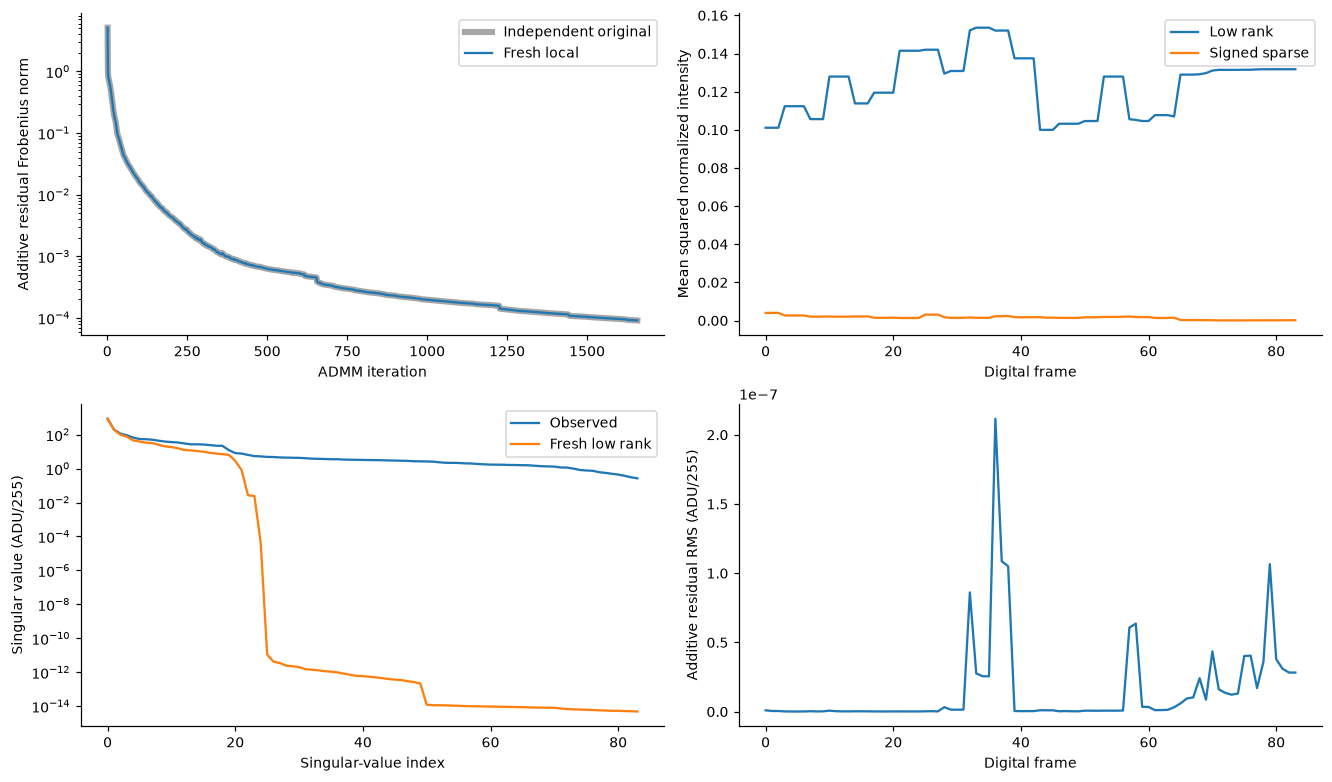

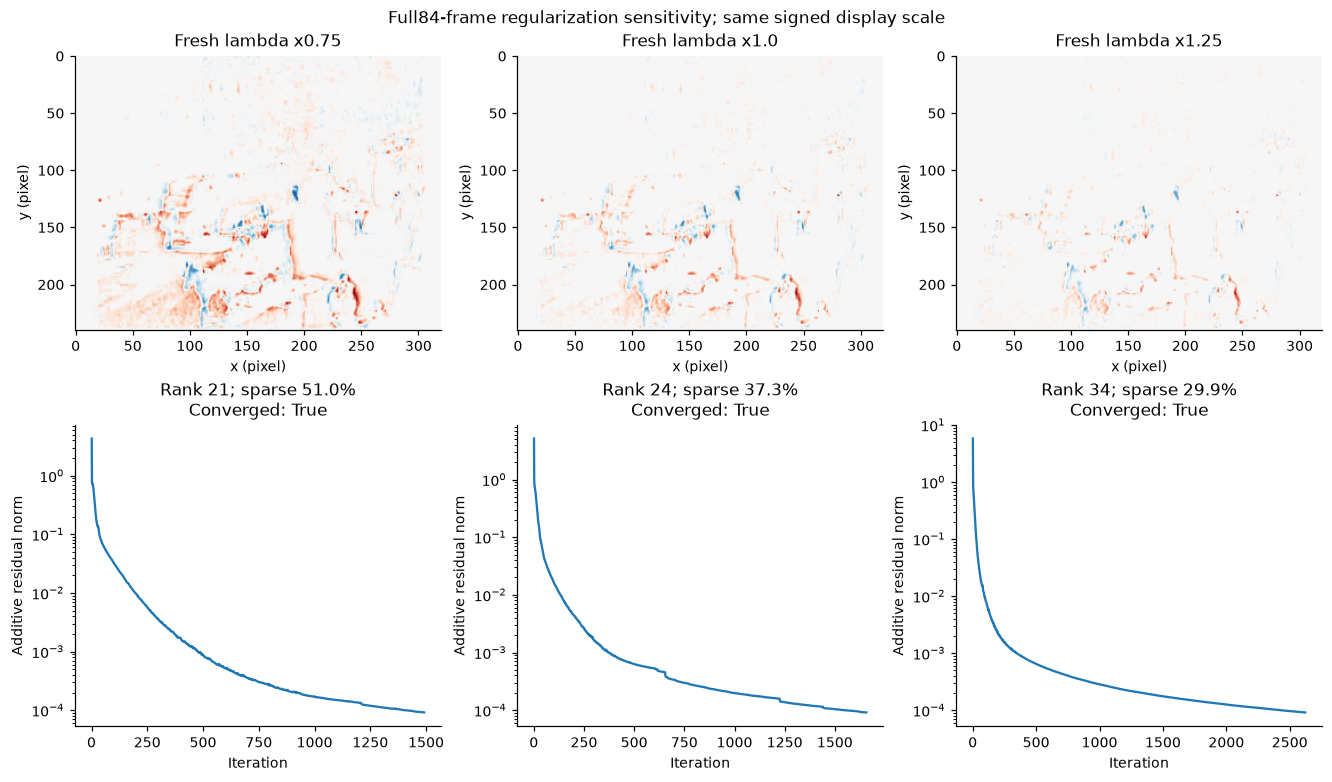

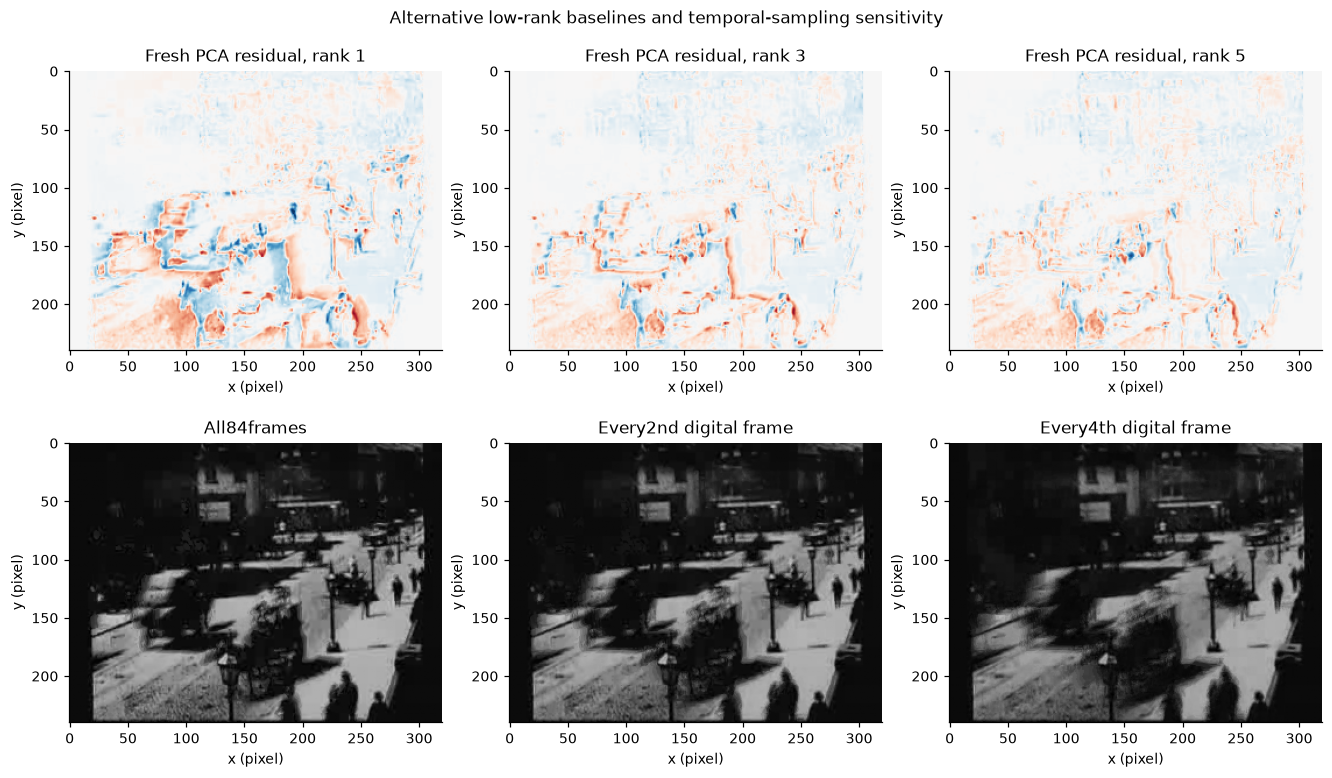

In [4]:
figs=figures(frames,result,diag,upstream,exp)
for fig in figs:
    plt.close(fig)
    display(fig)
destination=os.environ.get('IMAGING_REPORT_DIR')
if destination:
    export(figs,exp,destination)
    l=result['reconstruction'][0];s=result['sparse_component'][0];ids=exp['ids']
    np.savez_compressed(Path(destination)/'canonical_figure_source.npz',raw=frames[ids],low=l[ids],sparse=s[ids],fresh_trace=diag['history'],original_trace=upstream,low_energy=np.mean(l*l,axis=(1,2)),sparse_energy=np.mean(s*s,axis=(1,2)),residual_rms=np.sqrt(np.mean((frames/255-l-s)**2,axis=(1,2))),low_singular=np.linalg.svd(l.reshape(len(l),-1),compute_uv=False))
    Path(destination,'execution_measurements.json').write_text(json.dumps({'canonical_seconds':canonical_seconds,'experiments_seconds':experiment_seconds,'fresh':fresh,'judge':report},indent=2,allow_nan=False),encoding='utf8')


## 6. Conclusion

### Conclusion and limitations

The complete film is decomposed by an explicitly implemented nuclear/L1 model, independently checked against the original source and measured additive equation. Lambda and temporal sampling affect how motion/texture is assigned; PCA offers a different statistical separation. Even exact source parity and very small additive residual do not prove physical foreground recovery. Digital playback time is not a calibrated historical camera clock, uncertainty is not estimated, and no real component truth is available. See the executed measured tables above for this run rather than any published accuracy claim.

Paper: Candes et al., *Robust Principal Component Analysis?*, JACM2011, doi:10.1145/1970392.1970395, arXiv:0912.3599v1. Public-domain data: Louis Le Prince, *Traffic Crossing Leeds Bridge*1888, Wikimedia Commons. Exact source revision, licenses, hashes, original and cleaned commands, tolerance decisions and unresolved assumptions are in test/validation.md.

Low-rank and sparse arrays satisfy an additive statistical model, not physical foreground labels. Lambda and temporal-subset comparisons expose allocation sensitivity, while the full-frame residual tests the additive constraint. The 1888 camera exposure rate is not recovered from digital playback timing.
